# Práctica de PySpark ML

Dado el siguente dataset:

https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv

Cuyas variables representan:

| Variable | Descripción | Tipo de Dato | Valores / Rango |
| :--- | :--- | :--- | :--- |
| **`age`** | Edad del beneficiario principal. | Entero | Años de edad |
| **`sex`** | Género del contratante del seguro. | Categórico | `female`, `male` |
| **`bmi`** | Índice de masa corporal ($\text{kg/m}^2$). Mide la relación peso/altura (ideal: $18.5 - 24.9$). | Flotante | Continuo (ej. 28.50) |
| **`children`** | Número de hijos / dependientes cubiertos por la póliza. | Entero | $0, 1, 2, 3...$ |
| **`smoker`** | Indica si el beneficiario fuma. | Binario | `yes`, `no` |
| **`region`** | Área de residencia del beneficiario en EE. UU. | Categórico | `northeast`, `southeast`, `southwest`, `northwest` |
| **`charges`** | Costos médicos individuales facturados por el seguro (*Variable Objetivo*). | Flotante | Monto en USD ($) |

In [1]:
import pyspark.pandas as ps
from pyspark.sql import SparkSession

In [2]:
# Leer el fichero de datos
# getOrCreate: crea la sesión si no existe (en un kernel nuevo getActiveSession() devuelve None)
spark = SparkSession.builder.getOrCreate()
spark.conf.set(
    "spark.sql.ansi.enabled", "false"
)  # pandas-on-Spark no funciona con ANSI activado

df_insurance = ps.read_csv("insurance.csv")
df_insurance.head(10)


Picked up JAVA_TOOL_OPTIONS: -Djava.security.manager=allow


Picked up JAVA_TOOL_OPTIONS: -Djava.security.manager=allow


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/29 11:22:38 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


26/10/29 11:22:38 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
5,31,female,25.740,0,no,southeast,3756.62160
6,46,female,33.440,1,no,southeast,8240.58960
7,37,female,27.740,3,no,northwest,7281.50560
8,37,male,29.830,2,no,northeast,6406.41070
9,60,female,25.840,0,no,northwest,28923.13692


# EDA

## Analisis Descriptivo

Detección de nulos,shema,describe, outliers y explicación de outliers

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from pyspark.sql import functions as F

In [4]:
# TODO Información general y tipos de datos
df_insurance.info()

<class 'pyspark.pandas.frame.DataFrame'>
Index: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int32  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int32  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int32(2), object(3)

In [5]:
# TODO Estadísticas descriptivas
df_insurance.describe()

26/10/29 11:22:44 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.290000,0.000000,4738.268200
50%,39.000000,30.400000,1.000000,9377.904700
75%,51.000000,34.700000,2.000000,16657.717450
max,64.000000,53.130000,5.000000,63770.428010


In [6]:
# TODO Conteo de nulos
df_insurance.isnull().sum(axis=0)

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [7]:
# TODO Detección de outliers (método IQR) en charges y bmi
for col_name in ["charges", "bmi"]:
    q1 = df_insurance[col_name].quantile(0.25)
    q3 = df_insurance[col_name].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - (1.5 * iqr)
    upper_bound = q3 + (1.5 * iqr)

    outliers_df = df_insurance[
        (df_insurance[col_name] < lower_bound) | (df_insurance[col_name] > upper_bound)
    ]

    print(
        f"{col_name}: límite inferior {lower_bound:,.2f} | límite superior {upper_bound:,.2f} | outliers: {len(outliers_df)}"
    )

charges: límite inferior -13,140.91 | límite superior 34,536.89 | outliers: 139


bmi: límite inferior 13.67 | límite superior 47.32 | outliers: 9


Resolución: En `charges` hay un total de 139 valores fuera del rango $[Q_1 - 1.5\cdot IQR,\; Q_3 + 1.5\cdot IQR]$ (los límites se muestran arriba). Se revisa también `bmi` para comprobar si tiene valores atípicos.

### Investigación del outlier antes de la normalización

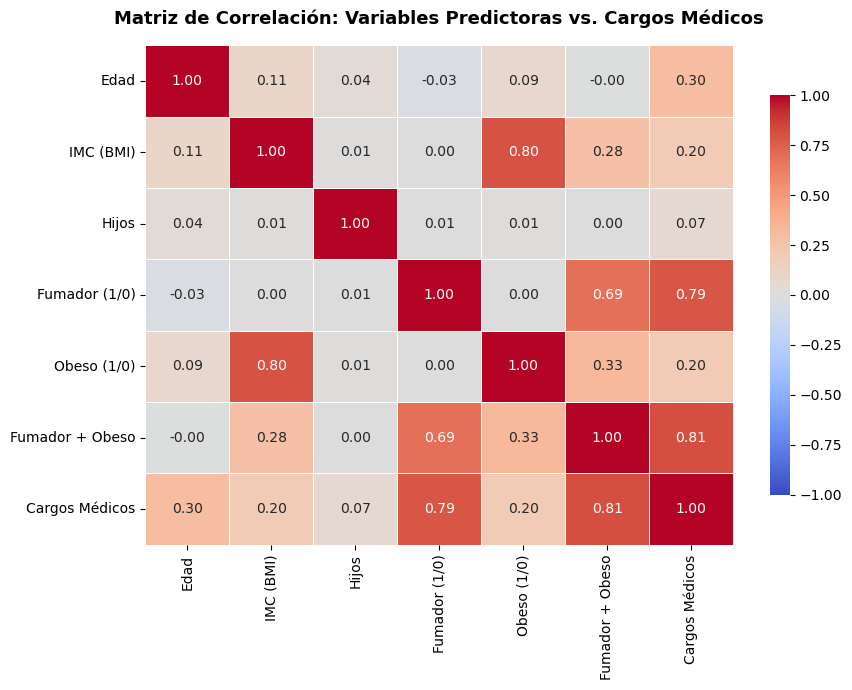

In [8]:
# TODO mapa de calor para ver las similitudes

# Crear las nuevas columnas
df_insurance["is_smoker"] = (df_insurance["smoker"] == "yes").astype(int)
df_insurance["is_obese"] = (df_insurance["bmi"] >= 30).astype(int)
df_insurance["smoker_obese_interaction"] = (
    df_insurance["is_smoker"] * df_insurance["is_obese"]
)

# Seleccionar las columnas de interés y convertirlas a un DataFrame local de pandas
cols_interes = [
    "age",
    "bmi",
    "children",
    "is_smoker",
    "is_obese",
    "smoker_obese_interaction",
    "charges",
]
df_corr = df_insurance[cols_interes].to_pandas()

# Renombrar las columnas
df_corr.columns = [
    "Edad",
    "IMC (BMI)",
    "Hijos",
    "Fumador (1/0)",
    "Obeso (1/0)",
    "Fumador + Obeso",
    "Cargos Médicos",
]

corr_matrix = df_corr.corr()

# heatmap
plt.figure(figsize=(9, 7))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmax=1,
    vmin=-1,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
)

plt.title(
    "Matriz de Correlación: Variables Predictoras vs. Cargos Médicos",
    fontsize=13,
    fontweight="bold",
    pad=15,
)
plt.tight_layout()
plt.show()

La matriz de correlación revela dos dinámicas distintas en la fijación de precios del seguro:

1. **Tendencia Base del Riesgo (`Edad` = 0.30):** La edad actúa como un factor estructural lineal. Aunque su correlación es moderada ($0.30$), es la variable encargada de explicar el incremento gradual del costo base a lo largo de la vida del asegurado.
2. **Disparadores de Costo Extremo (`Fumador + Obeso` = 0.81):** Representa el factor determinante que explica las facturas más elevadas y los *outliers*. La interacción entre tabaco y obesidad supera al tabaco individual ($0.79$) y a la obesidad aislada ($0.20$).

**Conclusión:** Se tendra en cuenta tanto la `Edad` (para capturar la tendencia base) como la interacción `Fumador + Obeso` (para explicar los valores extremos de `charges`).

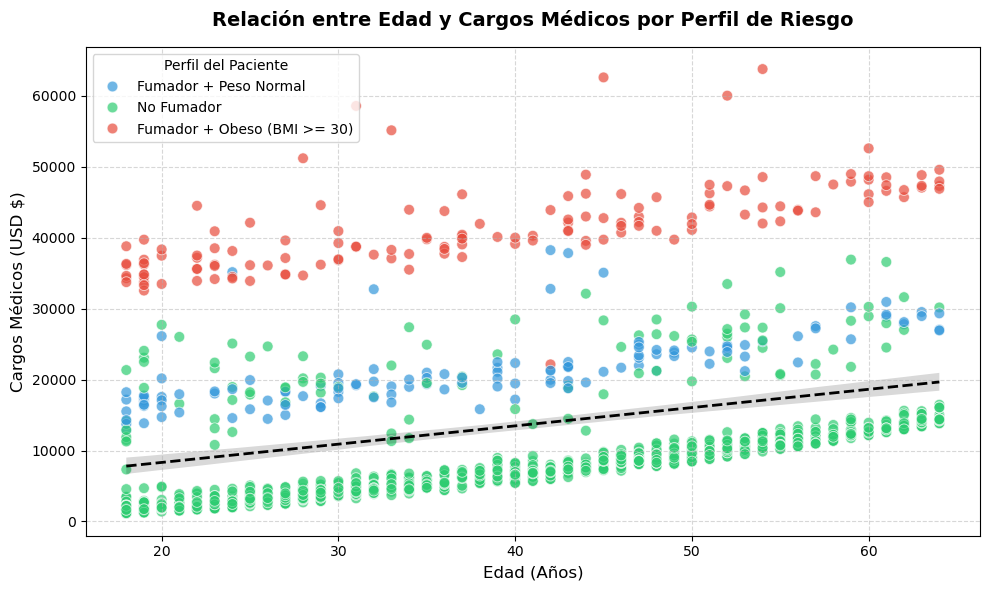

In [9]:
# TODO relacion entre edad y precio seguro medico

df_insurance["perfil_riesgo"] = "No Fumador"

# Aplicar las condiciones usando máscaras booleanas
cond_fumador_normal = (df_insurance["smoker"] == "yes") & (df_insurance["bmi"] < 30)
cond_fumador_obeso = (df_insurance["smoker"] == "yes") & (df_insurance["bmi"] >= 30)

df_insurance["perfil_riesgo"] = df_insurance["perfil_riesgo"].mask(
    cond_fumador_normal, "Fumador + Peso Normal"
)
df_insurance["perfil_riesgo"] = df_insurance["perfil_riesgo"].mask(
    cond_fumador_obeso, "Fumador + Obeso (BMI >= 30)"
)

# Seleccionar las columnas
cols = ["age", "charges", "perfil_riesgo"]
df_age_charges = df_insurance[cols].to_pandas()

# Grafica
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_age_charges,
    x="age",
    y="charges",
    hue="perfil_riesgo",
    palette={
        "No Fumador": "#2ecc71",
        "Fumador + Peso Normal": "#3498db",
        "Fumador + Obeso (BMI >= 30)": "#e74c3c",
    },
    alpha=0.7,
    s=60,
)

sns.regplot(
    data=df_age_charges,
    x="age",
    y="charges",
    scatter=False,
    color="black",
    line_kws={"linestyle": "--", "linewidth": 2, "label": "Tendencia Promedio (Edad)"},
)

plt.title(
    "Relación entre Edad y Cargos Médicos por Perfil de Riesgo",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Edad (Años)", fontsize=12)
plt.ylabel("Cargos Médicos (USD $)", fontsize=12)
plt.legend(title="Perfil del Paciente", loc="upper left")
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### Análisis de la Relación Edad vs. Cargos Médicos por Perfil de Riesgo

El gráfico de dispersión revela patrones estructurales clave sobre cómo se fijan las tarifas de la aseguradora:

* **Efecto de Incremento Lineal por Edad (Tendencia Base):** 
  En todas las categorías de pacientes se observa una **pendiente ascendente paralela e ininterrumpida**. A medida que la edad aumenta (de los 18 a los 64 años), el costo base de la póliza crece de forma sostenida (por ejemplo, en el grupo de no fumadores pasa de ~$2,500 en los más jóvenes a ~$12,000–$15,000 en los de mayor edad). Esto justifica mantener la `Edad` como variable Clave.

* **Estructura en 3 Niveles Claros (Franjas de Riesgo):**
  1. **Nivel Base (Verde - No Fumadores):** Concentra a la gran mayoría de la población con los costos más bajos del dataset ($2,000 - $15,000).
  2. **Nivel Intermedio (Azul - Fumadores con Peso Normal):** Presenta la misma pendiente pero desplazada hacia arriba, situándose en un rango de $15,000 a $30,000.
  3. **Nivel Crítico (Rojo - Fumadores Obesos):** Representa el escalón más alto, con valores que van desde los $35,000 hasta superar los $60,000.

* **Análisis de Outliers en No Fumadores (Puntos Verdes Dispersos):**
  Existe un pequeño subconjunto de puntos verdes que se desvían de la franja base y se mezclan en la zona media ($15,000 - $35,000). Una **hipótesis** razonable es que sean pacientes con intervenciones o tratamientos costosos imprevistos, pero el dataset no contiene esa información, así que no podemos confirmarlo.

**Conclusión para el Modelo:**
Mientras que el estilo de vida (`Fumador`) y la condición física (`Obesidad`) determinan a qué **escalón de precio** pertenece un paciente, la **`Edad`** determina la **posición exacta y el crecimiento del costo dentro de ese escalón**.

       smoker  total_personas   avg_charges  max_charges  min_charges  \
0  No Fumador            1064   8434.268298  36910.60803    1121.8739   
1     Fumador             274  32050.231832  63770.42801   12829.4551   

   mediana_charges  
0        7345.0840  
1       34439.8559  


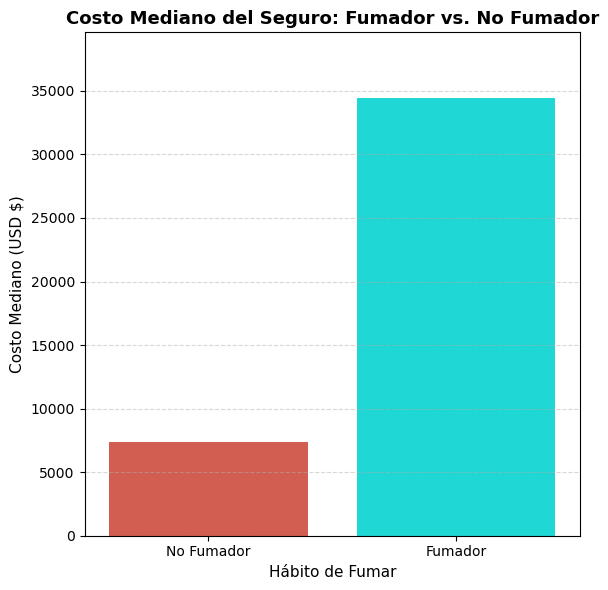

In [10]:
# warnings.filterwarnings("ignore", category=PandasAPIOnSparkAdviceWarning) # TODO desactivar para ver la alerta de que consume ram

# TODO comparamos smoker con el seguro

grupo_smoker = df_insurance.groupby("smoker")["charges"]

# Calcular las metricas
s_count = grupo_smoker.count().to_pandas()
s_mean = grupo_smoker.mean().to_pandas()
s_max = grupo_smoker.max().to_pandas()
s_min = grupo_smoker.min().to_pandas()
s_median = grupo_smoker.median().to_pandas()

df_smoker_summary_pd = pd.DataFrame(
    {
        "total_personas": s_count,
        "avg_charges": s_mean,
        "max_charges": s_max,
        "min_charges": s_min,
        "mediana_charges": s_median,
    }
).reset_index()

df_smoker_summary_pd["smoker"] = df_smoker_summary_pd["smoker"].map(
    {"yes": "Fumador", "no": "No Fumador"}
)

# Ver la tabla resumen por pantalla
print(df_smoker_summary_pd)

# grafica
plt.figure(figsize=(6, 6))
sns.barplot(
    x="smoker",
    y="mediana_charges",
    hue="smoker",
    legend=False,
    data=df_smoker_summary_pd,
    palette=["#e74c3c", "#00F6F2"],  # Rojo para fumador, azul para no fumador
)

plt.title(
    "Costo Mediano del Seguro: Fumador vs. No Fumador", fontsize=13, fontweight="bold"
)
plt.xlabel("Hábito de Fumar", fontsize=11)
plt.ylabel("Costo Mediano (USD $)", fontsize=11)
plt.ylim(
    0, df_smoker_summary_pd["mediana_charges"].max() * 1.15
)  # Dar un margen superior del 15%
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

**Resolución:** Se puede apreciar la diferencia de costo que hay entre una persona fumadora y una persona no fumadora. Hablamos de una cantidad que triplica un costo normal de un seguro.

--- Tabla Resumen ---
  smoker  is_obese  casos   avg_charges  median_charges
3    yes      True    145  41557.989840     40904.19950
2    yes     False    129  21363.217016     20167.33603
1     no      True    562   8842.691548      8068.18500
0     no     False    502   7977.029520      6753.03800


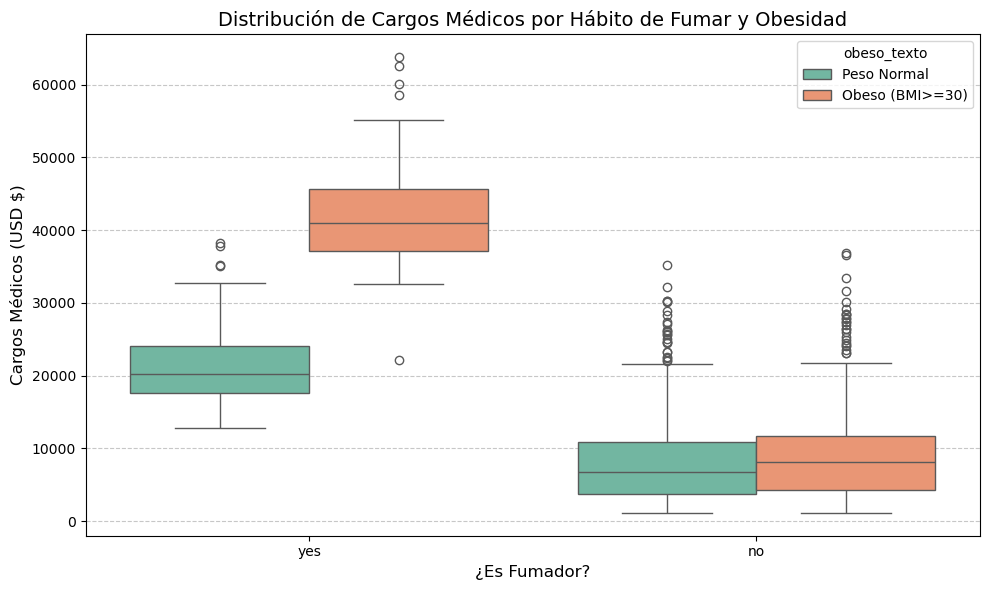

In [11]:
# Variable reutilizable
cond_obeso = df_insurance["bmi"] >= 30

# TODO comparar si fuma y esta obeso las consecuencias

# Crear la columna booleana de obesidad
df_insurance["is_obese"] = cond_obeso

# Agrupar por ambas columnas en pyspark.pandas
grupo_multi = df_insurance.groupby(["smoker", "is_obese"])["charges"]

s_casos = grupo_multi.count().to_pandas()
s_avg = grupo_multi.mean().to_pandas()
s_median = grupo_multi.median().to_pandas()

df_summary = pd.DataFrame(
    {"casos": s_casos, "avg_charges": s_avg, "median_charges": s_median}
).reset_index()

# Ordenar por avg_charges descendente
df_summary = df_summary.sort_values(by="avg_charges", ascending=False)

print("--- Tabla Resumen ---")
print(df_summary)


# Crear la columna de texto para la gráfica
df_insurance["obeso_texto"] = "Peso Normal"
df_insurance["obeso_texto"] = df_insurance["obeso_texto"].mask(
    cond_obeso, "Obeso (BMI>=30)"
)

df_plot = df_insurance[["smoker", "obeso_texto", "charges"]].to_pandas()

# grafica

plt.figure(figsize=(10, 6))
sns.boxplot(x="smoker", y="charges", hue="obeso_texto", data=df_plot, palette="Set2")

plt.title("Distribución de Cargos Médicos por Hábito de Fumar y Obesidad", fontsize=14)
plt.xlabel("¿Es Fumador?", fontsize=12)
plt.ylabel("Cargos Médicos (USD $)", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

En este gráfico se puede ver claramente a qué se debe la gran dispersión y diferencia de precios en la columna `charges`:

* **Efecto Multiplicador (Fumador + Obesidad):** Una persona fumadora y con obesidad ($\text{IMC} \ge 30$) triplica o cuadruplica los costos médicos (alcanzando de $35,000 a $45,000) frente a una persona no fumadora con esa misma obesidad (cuyos costos rondan los $8,000).
* **Impacto Directo del Tabaco:** El hábito de fumar por sí solo eleva drásticamente la tasa del seguro. Incluso en personas con peso normal, ser fumador incrementa el costo mediano a unos $20,000, en comparación con los $7,000 de un no fumador.
* **Análisis de Outliers (Puntos Aislados):** En el grupo de los **no fumadores**, la gran mayoría de los datos se concentran en la parte baja del gráfico (por debajo de los $10,000). Los puntos aislados (*outliers*) que flotan entre los $15,000 y $35,000 son pacientes no fumadores con costes muy superiores a los de su grupo. Podrían deberse a intervenciones o tratamientos costosos (hipótesis: el dataset no tiene esa información para confirmarlo).

# Normalización y Escalado

In [12]:
from pyspark.ml.feature import (
    StringIndexer,
    OneHotEncoder,
    VectorAssembler,
    StandardScaler,
)
from pyspark.ml import Pipeline
from pyspark.ml.regression import LinearRegression

In [13]:
df_insurance_ml = df_insurance.to_spark()
type(df_insurance_ml)

pyspark.sql.classic.dataframe.DataFrame

In [14]:
# Transformacion de la columna charges
df_insurance_ml = df_insurance_ml.withColumn("log_charges", F.log1p("charges"))

# División train/test ANTES de ajustar ningún transformador, para que el test no influya en el preprocesado
train_data, test_data = df_insurance_ml.randomSplit([0.8, 0.2], seed=42)

Explicación de porque uso log1p: Dado que la distribución de charges es altamente asimétrica y presenta outliers, se aplicó una transformación logarítmica (log1p) para estabilizar la varianza y mejorar el rendimiento del modelo lineal. Las predicciones finales se retransforman a la escala original de dólares mediante expm1 para su interpretación.

In [15]:
# Formalizacion de los datos

# Normalizamos por StringIndexer las col (Sex,Smoker,Region)

indexer = StringIndexer(
    inputCols=["sex", "smoker", "region"],
    outputCols=["sex_indexed", "smoker_indexed", "region_indexed"],
)

In [16]:
# Debido a que region consta de más de dos valores, se le aplica un OneHotEncoder
# dropLast=True generará 3 posiciones en lugar de 4 para evitar multicolinealidad

ohe_region = OneHotEncoder(
    inputCol="region_indexed", outputCol="region_ohe", dropLast=True
)

In [17]:
# Aplicamos a las columnas Age,BMI,Children el formato StandarScaler

assembler = VectorAssembler(
    inputCols=["age", "bmi", "children"], outputCol="numeric_features"
)

scaler = StandardScaler(
    inputCol="numeric_features",
    outputCol="numeric_features_scaled",
    withStd=True,
    withMean=True,
)

In [18]:
# Ensamblamos todas las columnas

final_assembler = VectorAssembler(
    inputCols=[
        "sex_indexed",
        "smoker_indexed",
        "region_ohe",
        "numeric_features_scaled",
    ],
    outputCol="features",
)

# Muestra las columnas originales junto con el vector final completo
# (el pipeline se ajusta solo con train; el test únicamente se transforma)

pipeline = Pipeline(stages=[indexer, ohe_region, assembler, scaler, final_assembler])

pipeline_model = pipeline.fit(train_data)
data = pipeline_model.transform(train_data)

data.select(
    "sex", "smoker", "region", "age", "bmi", "children", "features", "log_charges"
).show(10, truncate=False)

+------+------+---------+---+------+--------+---------------------------------------------------------------------------------+-----------------+
|sex   |smoker|region   |age|bmi   |children|features                                                                         |log_charges      |
+------+------+---------+---+------+--------+---------------------------------------------------------------------------------+-----------------+
|female|no    |southeast|18 |20.79 |0       |(8,[2,5,6,7],[1.0,-1.4891330250871504,-1.5993701397616729,-0.9066762902743918])  |7.383063625801425|
|female|yes   |northeast|18 |21.66 |0       |[0.0,1.0,0.0,0.0,1.0,-1.4891330250871504,-1.4580547645272246,-0.9066762902743918]|9.56692747005658 |
|female|no    |northeast|18 |25.08 |0       |(8,[4,5,6,7],[1.0,-1.4891330250871504,-0.902539151536636,-0.9066762902743918])   |7.695063433808059|
|female|no    |northeast|18 |26.315|0       |(8,[4,5,6,7],[1.0,-1.4891330250871504,-0.701936291290034,-0.9066762902743918]) 

# Division del dataset

In [19]:
from pyspark.ml.regression import LinearRegression
from pyspark.ml import Pipeline
from pyspark.ml.evaluation import RegressionEvaluator

resultados = []  # una fila por modelo y conjunto (train / test), siempre en USD


def metricas_usd(modelo, df, nombre, conjunto, log_target):
    """R2, RMSE y MAE en USD. Si el modelo predice log1p(charges) se deshace con expm1."""
    pred = modelo.transform(df)
    pred = pred.withColumn(
        "pred_USD", F.expm1("prediction") if log_target else F.col("prediction")
    )
    fila = {"modelo": nombre, "conjunto": conjunto}
    for m in ["r2", "rmse", "mae"]:
        ev = RegressionEvaluator(
            labelCol="charges", predictionCol="pred_USD", metricName=m
        )
        fila[m] = ev.evaluate(pred)
    resultados.append(fila)
    return fila

In [20]:
# PARTICIONADO (el split 80/20 con seed=42 ya se hizo antes de ajustar el preprocesado)
train_data = train_data.repartition(8)
test_data = test_data.repartition(8)

print(f"Registros para entrenamiento: {train_data.count()}")
print(f"Registros para prueba (evaluación): {test_data.count()}")

Registros para entrenamiento: 1108
Registros para prueba (evaluación): 230


#### Entrenamiento del modelo sin modificar el charges

In [21]:
lr_baseline = LinearRegression(
    featuresCol="features", labelCol="charges", regParam=0.01
)

pipeline_baseline = Pipeline(
    stages=[indexer, ohe_region, assembler, scaler, final_assembler, lr_baseline]
)

modelo_baseline = pipeline_baseline.fit(train_data)

for conjunto, df in [("train", train_data), ("test", test_data)]:
    f = metricas_usd(
        modelo_baseline, df, "1. Lineal sobre charges", conjunto, log_target=False
    )
    print(
        f"[{conjunto}] R2: {f['r2']:.4f} | RMSE: ${f['rmse']:,.2f} | MAE: ${f['mae']:,.2f}"
    )

26/10/29 11:22:48 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.JNIBLAS
26/10/29 11:22:48 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.lapack.JNILAPACK


[train] R2: 0.7404 | RMSE: $6,122.13 | MAE: $4,288.28


[test] R2: 0.7955 | RMSE: $5,660.56 | MAE: $3,960.01


**Resolución:** El modelo sin transformar `charges` explica aproximadamente el 80% de la varianza de `charges` en test (R²). El MAE indica que, de media, el error absoluto es de unos 4k USD; el RMSE es mayor porque eleva los errores al cuadrado y por tanto pesa más los fallos grandes. Este es el punto de partida con el que se compararán los demás modelos.

#### Entrenamiento del modelo usando logcharges

In [22]:
# DEFINIR EL MODELO Y EL PIPELINE
lr = LinearRegression(featuresCol="features", labelCol="log_charges", regParam=0.01)

final_pipeline = Pipeline(
    stages=[indexer, ohe_region, assembler, scaler, final_assembler, lr]
)

modelo_entrenado = final_pipeline.fit(train_data)

# Métricas en USD (expm1 sobre la predicción), comparables con el modelo anterior
for conjunto, df in [("train", train_data), ("test", test_data)]:
    f = metricas_usd(
        modelo_entrenado, df, "2. Lineal sobre log_charges", conjunto, log_target=True
    )
    print(
        f"[{conjunto}] R2 (USD): {f['r2']:.4f} | RMSE: ${f['rmse']:,.2f} | MAE: ${f['mae']:,.2f}"
    )

# R2 en escala logarítmica: solo informativo, NO es comparable con un R2 en USD
pred_log = modelo_entrenado.transform(test_data)
r2_log = RegressionEvaluator(
    labelCol="log_charges", predictionCol="prediction", metricName="r2"
).evaluate(pred_log)
print(f"\nR2 en escala log (test, no comparable con USD): {r2_log:.4f}")

[train] R2 (USD): 0.5228 | RMSE: $8,300.65 | MAE: $4,296.81


[test] R2 (USD): 0.6263 | RMSE: $7,652.56 | MAE: $3,651.67

R2 en escala log (test, no comparable con USD): 0.8119


**Interpretación de las métricas:**

* **R²:** proporción de la varianza de la variable objetivo que explica el modelo (no es un % de aciertos; eso sería la *accuracy* de clasificación).
* **RMSE:** error típico en USD; al elevar los errores al cuadrado, los fallos grandes pesan más.
* **MAE:** error absoluto medio en USD sobre **todos** los casos; no eleva al cuadrado, por eso los fallos grandes pesan menos que en el RMSE.

**¿Por qué el R² en escala log (~0.81) y el R² en USD no son comparables?** El primero mide la varianza de `log1p(charges)`, que está comprimida y es mucho más fácil de explicar; el segundo mide la varianza de `charges` en dólares, donde los valores extremos de los fumadores obesos dominan la varianza. Son dos variables objetivo distintas, así que solo se comparan los modelos con métricas en USD (R² en USD, RMSE y MAE), como se hace en la tabla final.

El `regParam=0.01` fue elegido a mano. Para ajustarlo correctamente se usa a continuación validación cruzada **solo sobre train** (ver https://spark.apache.org/docs/latest/ml-tuning.html y https://hyperopt.github.io/hyperopt/scaleout/spark/). El test se reserva para la evaluación final.

# EXTRA 

In [23]:
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder
from pyspark.ml.evaluation import RegressionEvaluator
from hyperopt import fmin, tpe, hp, Trials, STATUS_OK

In [24]:
# Para Hyperopt separamos una validación DENTRO de train; el test no se toca en la búsqueda
train_sub, val_sub = train_data.randomSplit([0.8, 0.2], seed=42)

pipeline_preproc = Pipeline(
    stages=[indexer, ohe_region, assembler, scaler, final_assembler]
)

# El preprocesado se ajusta solo con train_sub
pipeline_model_sub = pipeline_preproc.fit(train_sub)

train_sub_prep = pipeline_model_sub.transform(train_sub).persist()
val_sub_prep = pipeline_model_sub.transform(val_sub).persist()

In [25]:
# TODO apartado de Hyperopt (la pérdida se mide en validación, nunca en test)
import numpy as np

search_space = {
    "regParam": hp.loguniform("regParam", -9.0, 3.5),
    "elasticNetParam": hp.uniform("elasticNetParam", 0.0, 0.5),
}

# Mismo criterio que usará luego el CrossValidator: RMSE sobre log_charges
evaluator_val = RegressionEvaluator(
    labelCol="log_charges", predictionCol="prediction", metricName="rmse"
)


def objective_function(params):
    lr_h = LinearRegression(
        featuresCol="features",
        labelCol="log_charges",
        regParam=params["regParam"],
        elasticNetParam=params["elasticNetParam"],
    )
    modelo = lr_h.fit(train_sub_prep)
    loss = evaluator_val.evaluate(modelo.transform(val_sub_prep))
    return {"loss": loss, "status": STATUS_OK}


trials_normales = Trials()

mejor_resultado = fmin(
    fn=objective_function,
    space=search_space,
    algo=tpe.suggest,
    max_evals=20,
    trials=trials_normales,
    rstate=np.random.default_rng(42),  # semilla fija: resultados reproducibles
)

print(
    "Los mejores parámetros encontrados por Hyperopt (validación dentro de train):",
    mejor_resultado,
)

train_sub_prep.unpersist()
val_sub_prep.unpersist()

  0%|          | 0/20 [00:00<?, ?trial/s, best loss=?]

  5%|▌         | 1/20 [00:01<00:26,  1.41s/trial, best loss: 0.965702141505214]

 10%|█         | 2/20 [00:01<00:12,  1.45trial/s, best loss: 0.42762598931269363]

 15%|█▌        | 3/20 [00:01<00:07,  2.15trial/s, best loss: 0.4266544894376074] 

 20%|██        | 4/20 [00:01<00:05,  2.80trial/s, best loss: 0.4266544894376074]

...

 95%|█████████▌| 19/20 [00:04<00:00,  6.11trial/s, best loss: 0.42656528709484975]

100%|██████████| 20/20 [00:04<00:00,  6.03trial/s, best loss: 0.42656528709484975]

100%|██████████| 20/20 [00:04<00:00,  4.19trial/s, best loss: 0.42656528709484975]


Los mejores parámetros encontrados por Hyperopt (validación dentro de train): {'elasticNetParam': 0.020630178685456357, 'regParam': 0.0001904335864407711}


DataFrame[age: int, sex: string, bmi: double, children: int, smoker: string, region: string, charges: double, is_smoker: bigint, is_obese: boolean, smoker_obese_interaction: bigint, perfil_riesgo: string, obeso_texto: string, log_charges: double, sex_indexed: double, smoker_indexed: double, region_indexed: double, region_ohe: vector, numeric_features: vector, numeric_features_scaled: vector, features: vector]

In [26]:
# TODO GRID DE PARÁMETROS REAL + VALIDACIÓN CRUZADA SOBRE TRAIN
# El grid incluye varios valores y también los de Hyperopt, para compararlos con alternativas
reg_values = sorted(
    {0.001, 0.01, 0.1, 1.0, round(float(mejor_resultado["regParam"]), 4)}
)
en_values = sorted(
    {0.0, 0.25, 0.5, round(float(mejor_resultado["elasticNetParam"]), 4)}
)


def cross_validar(assembler_final, label="log_charges"):
    """CV solo sobre train; `label` es la variable objetivo (log_charges o charges)."""
    lr_cv = LinearRegression(featuresCol="features", labelCol=label)
    pipe = Pipeline(
        stages=[indexer, ohe_region, assembler, scaler, assembler_final, lr_cv]
    )
    grid = (
        ParamGridBuilder()
        .addGrid(lr_cv.regParam, reg_values)
        .addGrid(lr_cv.elasticNetParam, en_values)
        .build()
    )
    cv = CrossValidator(
        estimator=pipe,
        estimatorParamMaps=grid,
        evaluator=RegressionEvaluator(
            labelCol=label, predictionCol="prediction", metricName="rmse"
        ),
        numFolds=3,
        seed=42,
    )
    return cv.fit(train_data)  # solo train: el test no interviene


print(
    f"Buscando entre {len(reg_values) * len(en_values)} combinaciones de hiperparámetros (3 folds)..."
)
cv_model = cross_validar(final_assembler)

lr_opt = cv_model.bestModel.stages[-1]
print(f"Mejor regParam       : {lr_opt.getOrDefault('regParam')}")
print(f"Mejor elasticNetParam: {lr_opt.getOrDefault('elasticNetParam')}")
print(f"RMSE medio CV (log)  : {min(cv_model.avgMetrics):.4f}")

for conjunto, df in [("train", train_data), ("test", test_data)]:
    f = metricas_usd(
        cv_model.bestModel, df, "3. Log + CV (optimizado)", conjunto, log_target=True
    )
    print(
        f"[{conjunto}] R2 (USD): {f['r2']:.4f} | RMSE: ${f['rmse']:,.2f} | MAE: ${f['mae']:,.2f}"
    )

Buscando entre 20 combinaciones de hiperparámetros (3 folds)...


Mejor regParam       : 0.01
Mejor elasticNetParam: 0.5
RMSE medio CV (log)  : 0.4581


[train] R2 (USD): 0.5303 | RMSE: $8,234.95 | MAE: $4,260.32


[test] R2 (USD): 0.6358 | RMSE: $7,554.70 | MAE: $3,611.71


**Nota:** `fmin` usa `rstate=np.random.default_rng(42)` y el `CrossValidator` `seed=42`, por lo que los resultados son reproducibles. El test solo se usa para informar las métricas finales del modelo ya elegido.

## Modelo con la interacción fumador × obeso

En el EDA se vio que la interacción `smoker_obese_interaction` explica el salto de coste de los fumadores obesos (≈ 21 k$ de media si fuman y no son obesos, ≈ 42 k$ si fuman y son obesos), pero no estaba en el vector `features`. Se añade y se repite la misma búsqueda por validación cruzada sobre train, primero con la variable objetivo `log_charges` (como el modelo 3) y después con `charges` sin transformar.

In [27]:
final_assembler_inter = VectorAssembler(
    inputCols=[
        "sex_indexed",
        "smoker_indexed",
        "region_ohe",
        "numeric_features_scaled",
        "smoker_obese_interaction",
    ],
    outputCol="features",
)

cv_model_inter = cross_validar(final_assembler_inter)

lr_inter = cv_model_inter.bestModel.stages[-1]
print(f"Mejor regParam       : {lr_inter.getOrDefault('regParam')}")
print(f"Mejor elasticNetParam: {lr_inter.getOrDefault('elasticNetParam')}")

for conjunto, df in [("train", train_data), ("test", test_data)]:
    f = metricas_usd(
        cv_model_inter.bestModel,
        df,
        "4. Log + CV + interacción",
        conjunto,
        log_target=True,
    )
    print(
        f"[{conjunto}] R2 (USD): {f['r2']:.4f} | RMSE: ${f['rmse']:,.2f} | MAE: ${f['mae']:,.2f}"
    )

Mejor regParam       : 0.001
Mejor elasticNetParam: 0.5


[train] R2 (USD): 0.4553 | RMSE: $8,868.57 | MAE: $4,109.07


[test] R2 (USD): 0.3889 | RMSE: $9,785.70 | MAE: $4,299.18


**Resultado inesperado:** al añadir la interacción al modelo logarítmico, el RMSE y el R² en USD **empeoran** (el MAE solo mejora ligeramente). No es un fallo de implementación: con `log_charges` el modelo es *multiplicativo* (los efectos se multiplican al deshacer el logaritmo con `expm1`), y al sumar además la interacción en escala log se sobreestima el coste de los fumadores obesos, que son pocos pero de importes muy altos. Un puñado de errores muy grandes basta para disparar el RMSE. El efecto que se ha observado en el EDA (≈ +20 k$ al sumar obesidad en los fumadores) es **aditivo en dólares**, por lo que encaja mejor con un modelo lineal sobre `charges` sin transformar. Se prueba a continuación.

In [28]:
# Modelo 5: interacción + objetivo SIN transformar (efecto aditivo en USD), misma CV sobre train
cv_model_inter_usd = cross_validar(final_assembler_inter, label="charges")

lr_inter_usd = cv_model_inter_usd.bestModel.stages[-1]
print(f"Mejor regParam       : {lr_inter_usd.getOrDefault('regParam')}")
print(f"Mejor elasticNetParam: {lr_inter_usd.getOrDefault('elasticNetParam')}")

for conjunto, df in [("train", train_data), ("test", test_data)]:
    f = metricas_usd(
        cv_model_inter_usd.bestModel,
        df,
        "5. Lineal + CV + interacción (sin log)",
        conjunto,
        log_target=False,
    )
    print(
        f"[{conjunto}] R2 (USD): {f['r2']:.4f} | RMSE: ${f['rmse']:,.2f} | MAE: ${f['mae']:,.2f}"
    )

Mejor regParam       : 1.0
Mejor elasticNetParam: 0.5


[train] R2 (USD): 0.8559 | RMSE: $4,561.32 | MAE: $2,560.66


[test] R2 (USD): 0.8954 | RMSE: $4,047.87 | MAE: $2,305.27


## Comparación final (métricas en USD, train y test)

In [29]:
df_res = pd.DataFrame(resultados)
tabla = df_res.pivot(index="modelo", columns="conjunto", values=["r2", "rmse", "mae"])
tabla = tabla.reindex(
    columns=pd.MultiIndex.from_product([["r2", "rmse", "mae"], ["train", "test"]])
)
tabla.round(4)

r2               rmse             \
                                         train    test      train       test   
modelo                                                                         
1. Lineal sobre charges                 0.7404  0.7955  6122.1303  5660.5592   
2. Lineal sobre log_charges             0.5228  0.6263  8300.6471  7652.5644   
3. Log + CV (optimizado)                0.5303  0.6358  8234.9481  7554.6953   
4. Log + CV + interacción               0.4553  0.3889  8868.5679  9785.6976   
5. Lineal + CV + interacción (sin log)  0.8559  0.8954  4561.3153  4047.8711   

                                              mae             
                                            train       test  
modelo                                                        
1. Lineal sobre charges                 4288.2850  3960.0071  
2. Lineal sobre log_charges             4296.8074  3651.6748  
3. Log + CV (optimizado)                4260.3204  3611.7089  
4. Log + CV + interacción               4109.0712  4299.1778  
5. Lineal + CV + interacción (sin log)  2560.6619  2305.2700

## Conclusión

Todas las métricas están en USD y se calculan sobre train y test, de modo que los cinco modelos son comparables (ver tabla). Los hiperparámetros se eligieron con validación cruzada sobre train; el test se usa una sola vez para informar el resultado final.

| Modelo | R² test | RMSE test | MAE test |
|---|---|---|---|
| 1. Lineal sobre `charges` | 0.796 | 5,661 $ | 3,960 $ |
| 2. Lineal sobre `log_charges` | 0.626 | 7,653 $ | 3,652 $ |
| 3. Log + CV | 0.636 | 7,555 $ | 3,612 $ |
| 4. Log + CV + interacción | 0.389 | 9,786 $ | 4,299 $ |
| **5. Lineal + CV + interacción (sin log)** | **0.895** | **4,048 $** | **2,305 $** |

* **Mejor modelo:** el 5. Frente al punto de partida (modelo 1) reduce el RMSE un 29 % y el MAE un 42 %, y explica el 90 % de la varianza de `charges` en test.
* **La interacción es lo que más aporta, pero solo en la escala correcta:** el salto de coste de los fumadores obesos (≈ 21 k$ frente a ≈ 42 k$ de media) es aditivo en dólares. Con el objetivo en logaritmo, la misma interacción hace que el modelo sobreestime a ese grupo al deshacer el logaritmo y el RMSE empeora (modelo 4).
* **La transformación logarítmica no ayudó aquí:** mejora ligeramente el MAE (la mayoría de los casos, de importes bajos, se predicen mejor) pero empeora el RMSE y el R² en USD, porque falla en los pocos casos de importe muy alto, que son los que dominan el coste.
* **Efecto de la regularización:** la validación cruzada aporta poco al modelo 3 (R² 0.626 → 0.636), como es habitual en una regresión lineal con pocas variables.
* **Sobreajuste:** train y test están próximos (R² 0.856 y 0.895; el test es pequeño, ≈ 270 filas, y la diferencia entra en su variabilidad), así que no hay señal de sobreajuste.
* **Escala del objetivo:** el R² de `log_charges` (~0.81) no se compara con el R² en USD; solo cuenta el R² en USD de la tabla.

Limitaciones: el mejor `regParam` del modelo 5 es 1.0, el extremo superior del grid, por lo que habría que ampliarlo; los hiperparámetros de Hyperopt se buscaron sobre `log_charges` y solo se usaron como un candidato más; no se han revisado los residuos ni se han probado otras interacciones (p. ej. `age` × fumador) o modelos no lineales; y todo se basa en una sola partición train/test.